# Job Market Analysis and Recommendation System



In [ ]:
import os
import html
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy import stats
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

results = {}

## 1. Loading the data

In [ ]:
path = 'upwork_job.csv' if os.path.exists('upwork_job.csv') else '../data/upwork_job.csv'
df = pd.read_csv(path)
print(df.shape)
df.head()

(244828, 8)


,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country
0,Experienced Media Buyer For Solar Pannel and R...,https://www.upwork.com/jobs/Experienced-Media-...,2024-02-17 09:09:54+00:00,False,NaN,NaN,500.0,NaN
1,Full Stack Developer,https://www.upwork.com/jobs/Full-Stack-Develop...,2024-02-17 09:09:17+00:00,False,NaN,NaN,1100.0,United States
2,SMMA Bubble App,https://www.upwork.com/jobs/SMMA-Bubble-App_%7...,2024-02-17 09:08:46+00:00,True,10.0,30.0,NaN,United States
3,Talent Hunter Specialized in Marketing,https://www.upwork.com/jobs/Talent-Hunter-Spec...,2024-02-17 09:08:08+00:00,True,NaN,NaN,NaN,United States
4,Data Engineer,https://www.upwork.com/jobs/Data-Engineer_%7E0...,2024-02-17 09:07:42+00:00,False,NaN,NaN,650.0,India


In [ ]:
df.info()
print()
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 244828 entries, 0 to 244827
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   title           244827 non-null  str    
 1   link            244827 non-null  str    
 2   published_date  244828 non-null  str    
 3   is_hourly       244828 non-null  bool   
 4   hourly_low      102422 non-null  float64
 5   hourly_high     98775 non-null   float64
 6   budget          103891 non-null  float64
 7   country         239751 non-null  str    
dtypes: bool(1), float64(3), str(4)
memory usage: 13.3 MB

title                  1
link                   1
published_date         0
is_hourly              0
hourly_low        142406
hourly_high       146053
budget            140937
country             5077
dtype: int64


## 2. Data cleaning

In [ ]:
# date column to proper datetime
df['published_date'] = pd.to_datetime(df['published_date'])
df['date'] = df['published_date'].dt.tz_convert(None).dt.normalize()

# titles have html text like &amp; so clean it
df['title'] = df['title'].fillna('').apply(html.unescape)
df['title_clean'] = df['title'].str.lower().str.strip()

# remove duplicate rows and empty titles
before = len(df)
df = df.drop_duplicates(subset=['title_clean', 'published_date'])
df = df[df['title_clean'] != '']
print('rows removed:', before - len(df))

# hourly rate = average of low and high
df['hourly_rate'] = df[['hourly_low', 'hourly_high']].mean(axis=1)

# very big values are mostly typing mistakes, so remove them
df.loc[df['hourly_rate'] > 150, 'hourly_rate'] = np.nan
df.loc[df['budget'] > 5000, 'budget'] = np.nan

rows removed: 18


In [ ]:
# jobs per day, to check the date range
daily_jobs = df.groupby('date').size()
print(daily_jobs.head(15))

date
2023-11-02    1
2023-12-02    1
2023-12-05    1
2023-12-11    1
2023-12-13    1
2023-12-16    1
2023-12-20    1
2023-12-21    1
2023-12-25    1
2023-12-27    1
2023-12-28    1
2024-01-02    2
2024-01-03    1
2024-01-05    1
2024-01-06    1
dtype: int64


In [ ]:
df = df[df['date'] >= '2024-02-13'].copy()

# week number: 7 day blocks starting from 13 Feb (week 6 has only 6 days)
df['week'] = (df['date'] - pd.Timestamp('2024-02-13')).dt.days // 7 + 1
df['month'] = df['date'].dt.strftime('%b %Y')

week_start = df.groupby('week')['date'].min().dt.strftime('%d %b')
print(df.shape)
print(week_start.to_dict())

(244527, 13)
{1: '13 Feb', 2: '20 Feb', 3: '27 Feb', 4: '05 Mar', 5: '12 Mar', 6: '19 Mar'}


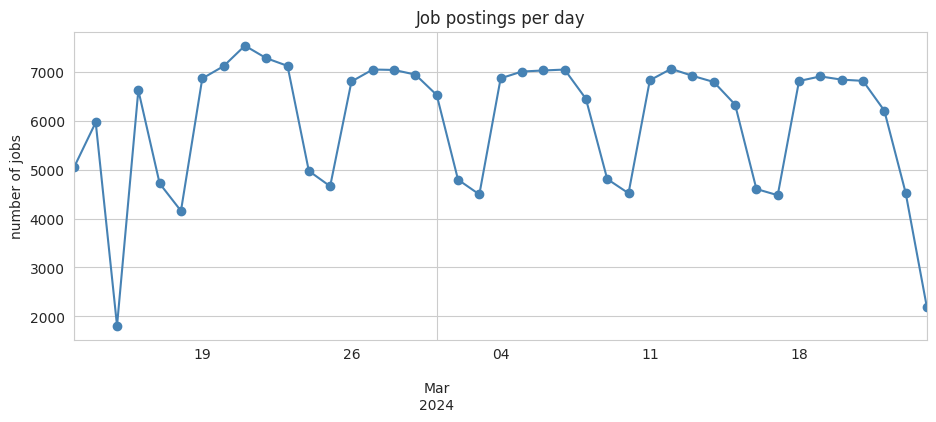

In [ ]:
daily_jobs = df.groupby('date').size()
daily_jobs.plot(figsize=(11, 4), marker='o', color='steelblue')
plt.title('Job postings per day')
plt.ylabel('number of jobs')
plt.xlabel('')
plt.show()

### Creating job categories


In [ ]:
category_patterns = {
    'AI & Machine Learning': r"\bai\b|a\.i\.|chatgpt|\bgpt|machine learning|\bllm\b|artificial intelligence|openai|prompt engineer|deep learning|midjourney|stable diffusion|\bnlp\b|computer vision|chatbot|\bml\b",
    'Data & Analytics': r"\bdata\b|analytics|analyst|\bsql\b|power bi|tableau|excel|scraping|scraper|dashboard|google sheets|spreadsheet|\betl\b|database|looker",
    'Mobile App Development': r"\bapp\b|\bapps\b|mobile|android|\bios\b|flutter|react native|swift|kotlin|iphone",
    'E-commerce': r"shopify|amazon|ebay|etsy|dropship|woocommerce|e-commerce|ecommerce|\bfba\b|walmart|tiktok shop|online store",
    'Web & Software Development': r"web|wordpress|\bwix\b|webflow|developer|programmer|\bphp\b|python|react|node|javascript|laravel|full stack|fullstack|backend|front end|frontend|software|\bapi\b|\bcode|coder|django|\.net|\bjava\b|html|\bcss\b|bubble|devops|\baws\b|cloud|engineer|saas|plugin|zapier|automation|crm|gohighlevel|\bseo\b",
    '3D, Game & Architecture': r"\b3d\b|\bcad\b|architect|revit|blender|autocad|interior|render|\bgame|unity|unreal|solidworks|sketchup",
    'Audio & Music': r"music|audio|voice|singer|\bsong|sound|mixing|\bbeat|producer|vocal|podcast",
    'Video Editing & Animation': r"video|youtube|editor|editing|animat|reel|tiktok|motion graphic|after effects|premiere|\bvfx\b|shorts|capcut|videographer|filming|ugc|\bvsl\b",
    'Graphic Design': r"design|logo|graphic|illustrat|brand|canva|photoshop|figma|\bui\b|\bux\b|thumbnail|packaging|poster|flyer|artist|drawing|\bart\b|photo",
    'Writing & Translation': r"writer|writing|copywrit|content|blog|article|ghostwrit|proofread|translat|transcri|script|ebook|e-book|\bbook|resume|\bcv\b|author|editor|newsletter",
    'Sales & Lead Generation': r"\bsales|\blead|appointment|\bcold|outreach|closer|\bsdr\b|\bb2b\b|setter|prospect|linkedin",
    'Social Media & Marketing': r"marketing|marketer|social media|\bads\b|\bppc\b|facebook|google ads|email|growth|campaign|media buyer|funnel|affiliate|influencer|instagram|community manager|advertis",
    'Customer Support': r"customer|support|service|chat agent|call center|receptionist|\bagent\b",
    'Finance & Accounting': r"account|bookkeep|\btax\b|finance|financial|quickbooks|crypto|trading|forex|invest|payroll|\bxero\b|blockchain|nft|web3",
    'Virtual Assistant & Admin': r"virtual assistant|\bva\b|assistant|admin|data entry|secretary|manager|coordinator|scheduler|research|organizer|project management|\bpm\b|recruit",
}

df['category'] = 'Other'
for cat, pattern in category_patterns.items():
    match = df['title_clean'].str.contains(pattern, regex=True)
    df.loc[(df['category'] == 'Other') & match, 'category'] = cat

cat_count = df['category'].value_counts()
print((cat_count / len(df) * 100).round(1))

category
Web & Software Development    19.4
Other                         15.7
Graphic Design                 9.8
Video Editing & Animation      9.7
Writing & Translation          7.7
Data & Analytics               5.1
Social Media & Marketing       4.9
E-commerce                     4.8
Mobile App Development         4.6
Sales & Lead Generation        4.3
Virtual Assistant & Admin      3.4
3D, Game & Architecture        3.0
AI & Machine Learning          2.4
Finance & Accounting           2.1
Audio & Music                  1.9
Customer Support               1.3
Name: count, dtype: float64


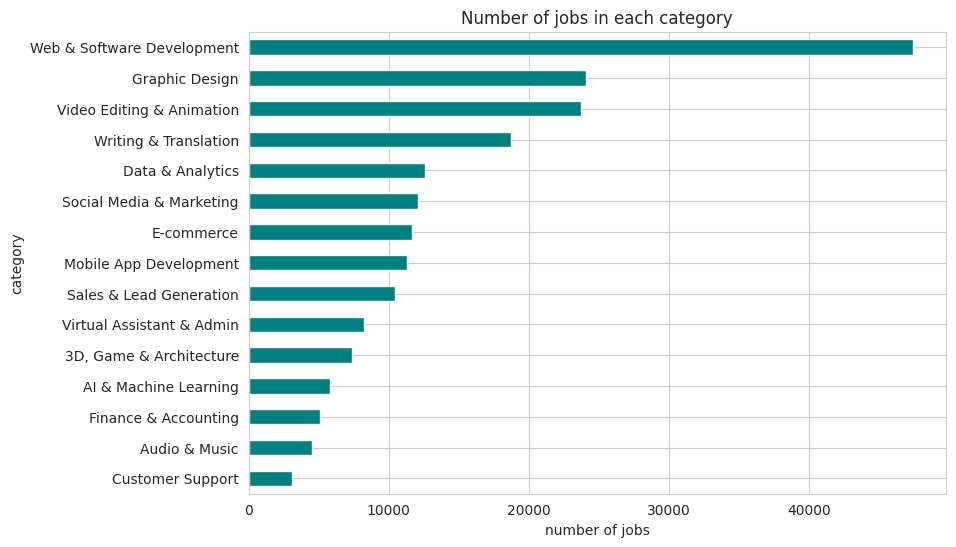

In [ ]:
cat_count.drop('Other').sort_values().plot(kind='barh', color='teal', figsize=(9, 6))
plt.title('Number of jobs in each category')
plt.xlabel('number of jobs')
plt.show()

results['category_count'] = cat_count.drop('Other').to_dict()
results['total_jobs'] = int(len(df))
results['other_share'] = round(float(cat_count['Other'] / len(df) * 100), 1)

## Correlation between job title keywords and offered salary



In [ ]:
hourly = df[df['hourly_rate'].notnull()].copy()
fixed = df[df['budget'].notnull()].copy()
print('hourly jobs with rate:', len(hourly))
print('fixed price jobs with budget:', len(fixed))
print()
print(hourly['hourly_rate'].describe().round(2))

hourly jobs with rate: 101539
fixed price jobs with budget: 102225

count    101539.00
mean         27.52
std          21.41
min           3.00
25%          12.50
50%          22.50
75%          35.00
max         150.00
Name: hourly_rate, dtype: float64


In [ ]:
vec = CountVectorizer(stop_words='english', binary=True, min_df=300, token_pattern=r'[a-z]{3,}')
X = vec.fit_transform(hourly['title_clean'])
words = vec.get_feature_names_out()
y = hourly['hourly_rate'].values
print('keywords used:', len(words))


def keyword_table(X, y, words):
    n = len(y)
    count = np.array(X.sum(axis=0)).ravel()
    sum_with = X.T.dot(y)
    avg_with = sum_with / count
    avg_without = (y.sum() - sum_with) / (n - count)
    p = count / n
    # point-biserial correlation
    corr = (avg_with - avg_without) / y.std() * np.sqrt(p * (1 - p))
    table = pd.DataFrame({'keyword': words, 'jobs': count, 'avg_with': avg_with,
                          'avg_without': avg_without, 'correlation': corr})
    return table


kw = keyword_table(X, y, words)
top_pos = kw.sort_values('correlation', ascending=False).head(15)
top_neg = kw.sort_values('correlation').head(15)
top_pos.round(3)

keywords used: 280


,keyword,jobs,avg_with,avg_without,correlation
242,tax,639,51.613,27.366,0.090
55,consultant,890,46.704,27.349,0.084
261,videographer,405,52.015,27.420,0.072
56,consultation,329,53.027,27.435,0.068
139,legal,396,46.500,27.444,0.055
58,contract,363,45.252,27.455,0.050
90,engineer,1516,36.108,27.388,0.049
181,photographer,329,45.965,27.458,0.049
106,financial,535,41.536,27.444,0.048
101,expert,7152,31.188,27.240,0.047


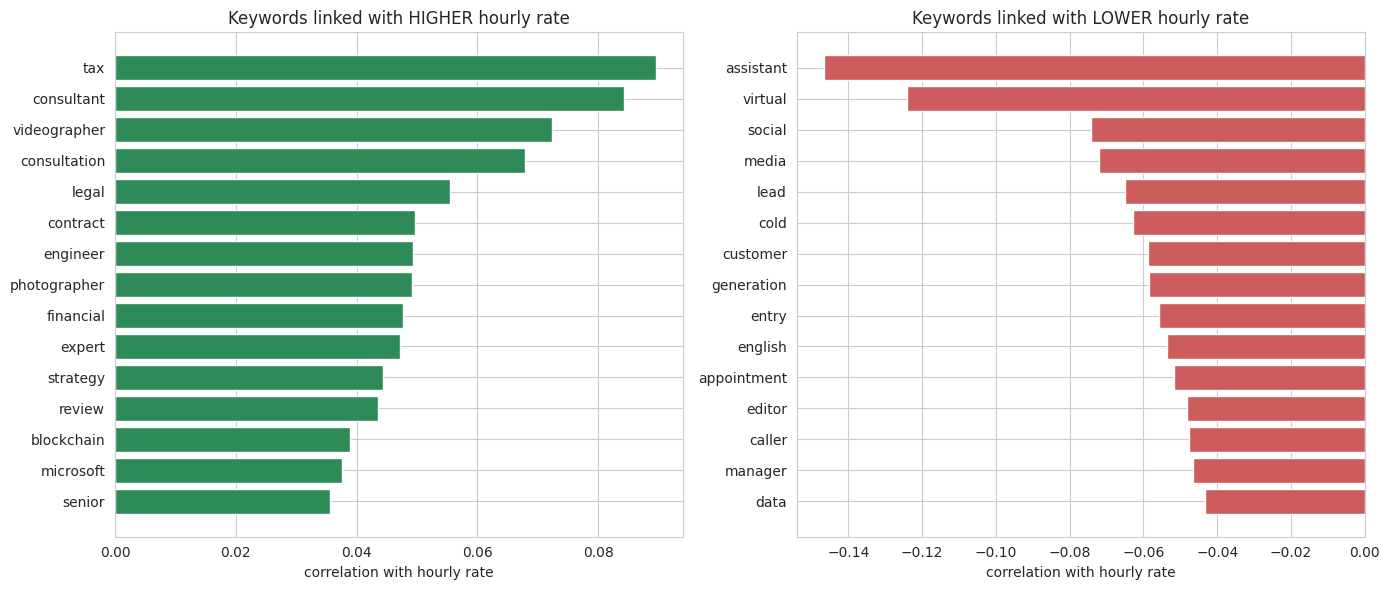

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(top_pos['keyword'][::-1], top_pos['correlation'][::-1], color='seagreen')
axes[0].set_title('Keywords linked with HIGHER hourly rate')
axes[1].barh(top_neg['keyword'][::-1], top_neg['correlation'][::-1], color='indianred')
axes[1].set_title('Keywords linked with LOWER hourly rate')
for ax in axes:
    ax.set_xlabel('correlation with hourly rate')
plt.tight_layout()
plt.show()

results['t1_pos'] = top_pos[['keyword', 'correlation', 'avg_with']].round(3).to_dict('records')
results['t1_neg'] = top_neg[['keyword', 'correlation', 'avg_with']].round(3).to_dict('records')
results['avg_hourly_all'] = round(float(y.mean()), 2)

In [ ]:
# is the difference real? Mann-Whitney test on the strongest keywords
Xc = X.tocsc()
word_list = list(words)
test_rows = []
for word in list(top_pos['keyword'][:5]) + list(top_neg['keyword'][:5]):
    j = word_list.index(word)
    has_word = Xc[:, j].toarray().ravel() == 1
    u, p = stats.mannwhitneyu(y[has_word], y[~has_word])
    test_rows.append({'keyword': word, 'median_with': np.median(y[has_word]),
                      'median_without': np.median(y[~has_word]), 'p_value': p})
pd.DataFrame(test_rows)

,keyword,median_with,median_without,p_value
0,tax,50.0,22.5,2.157043e-92
1,consultant,40.0,22.5,8.091225e-119
2,videographer,42.5,22.5,1.953559e-108
3,consultation,47.5,22.5,4.011907e-63
4,legal,31.0,22.5,7.692723e-20
5,assistant,8.5,22.5,0.000000e+00
6,virtual,7.5,22.5,0.000000e+00
7,social,16.5,22.5,4.872993e-168
8,media,16.5,22.5,3.032721e-157
9,lead,10.0,22.5,2.265817e-205


### Hourly rate by job category

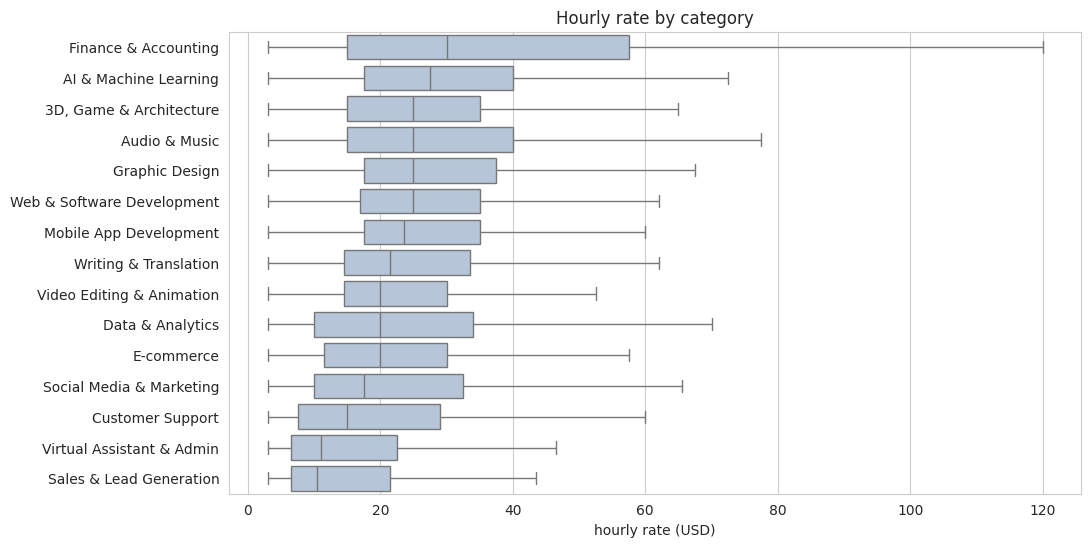

Kruskal-Wallis test: H = 6670.6 , p-value = 0.0


In [ ]:
big_cats = [c for c in cat_count.index if c != 'Other']
order = hourly[hourly['category'].isin(big_cats)].groupby('category')['hourly_rate'].median().sort_values(ascending=False).index

plt.figure(figsize=(11, 6))
sns.boxplot(data=hourly[hourly['category'].isin(big_cats)], y='category', x='hourly_rate',
            order=order, showfliers=False, color='lightsteelblue')
plt.title('Hourly rate by category')
plt.xlabel('hourly rate (USD)')
plt.ylabel('')
plt.show()

groups = [g['hourly_rate'].values for _, g in hourly[hourly['category'].isin(big_cats)].groupby('category')]
h_stat, p_val = stats.kruskal(*groups)
print('Kruskal-Wallis test: H =', round(h_stat, 1), ', p-value =', p_val)

cat_rate = hourly[hourly['category'].isin(big_cats)].groupby('category')['hourly_rate'].median().sort_values(ascending=False)
results['t1_cat_rate'] = cat_rate.round(1).to_dict()

### Same analysis for fixed price jobs

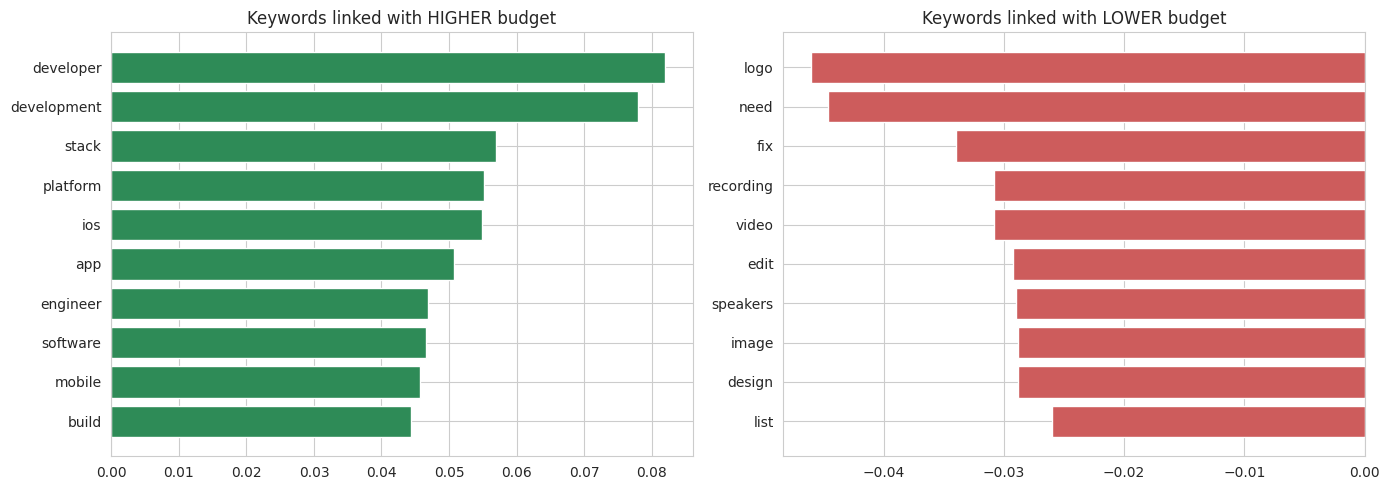

In [ ]:
Xf = CountVectorizer(stop_words='english', binary=True, min_df=300, token_pattern=r'[a-z]{3,}')
Xf_matrix = Xf.fit_transform(fixed['title_clean'])
kw_fixed = keyword_table(Xf_matrix, fixed['budget'].values, Xf.get_feature_names_out())

fp = kw_fixed.sort_values('correlation', ascending=False).head(10)
fn = kw_fixed.sort_values('correlation').head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(fp['keyword'][::-1], fp['correlation'][::-1], color='seagreen')
axes[0].set_title('Keywords linked with HIGHER budget')
axes[1].barh(fn['keyword'][::-1], fn['correlation'][::-1], color='indianred')
axes[1].set_title('Keywords linked with LOWER budget')
plt.tight_layout()
plt.show()

results['t1_fixed_pos'] = fp[['keyword', 'correlation', 'avg_with']].round(3).to_dict('records')
results['t1_fixed_neg'] = fn[['keyword', 'correlation', 'avg_with']].round(3).to_dict('records')

## Task 2: Emerging job categories based on posting frequency



In [ ]:
week_cat = pd.crosstab(df['week'], df['category'], normalize='index') * 100
week_cat = week_cat.drop(columns='Other')

first_half = week_cat.loc[[1, 2, 3]].mean()
second_half = week_cat.loc[[4, 5, 6]].mean()
growth = pd.DataFrame({'jobs': cat_count.drop('Other'),
                       'share_first_3_weeks': first_half,
                       'share_last_3_weeks': second_half})
growth['growth_%'] = (growth['share_last_3_weeks'] - growth['share_first_3_weeks']) / growth['share_first_3_weeks'] * 100
growth = growth.sort_values('growth_%', ascending=False)
growth.round(2)

,jobs,share_first_3_weeks,share_last_3_weeks,growth_%
category,,,,
Customer Support,3093,1.21,1.31,7.70
AI & Machine Learning,5817,2.31,2.46,6.48
Social Media & Marketing,12086,4.84,5.06,4.71
Finance & Accounting,5089,2.04,2.11,3.70
Graphic Design,24057,9.70,9.99,2.98
Mobile App Development,11290,4.58,4.65,1.72
Web & Software Development,47390,19.27,19.54,1.45
Virtual Assistant & Admin,8213,3.33,3.38,1.28
Video Editing & Animation,23694,9.62,9.74,1.25


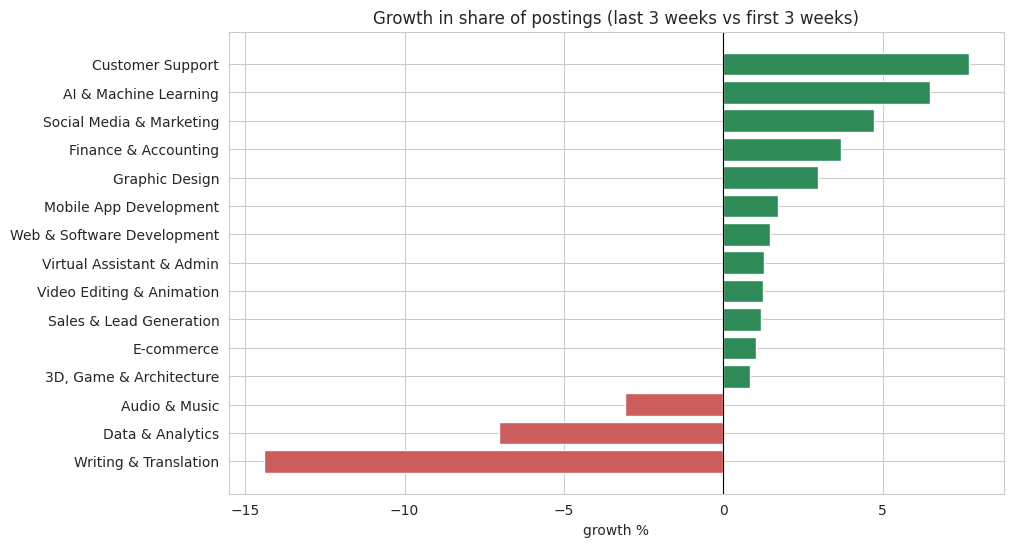

In [ ]:
colors = ['seagreen' if g > 0 else 'indianred' for g in growth['growth_%']]
plt.figure(figsize=(10, 6))
plt.barh(growth.index[::-1], growth['growth_%'][::-1], color=colors[::-1])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Growth in share of postings (last 3 weeks vs first 3 weeks)')
plt.xlabel('growth %')
plt.show()

results['t2_growth'] = growth['growth_%'].round(1).to_dict()

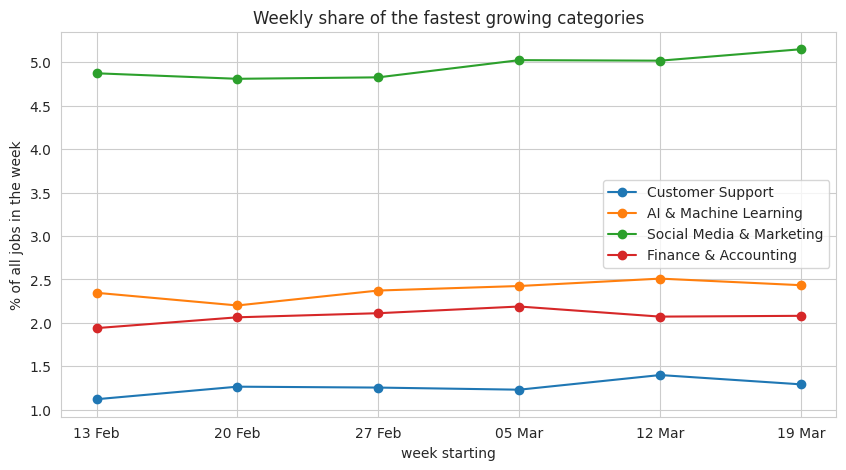

In [ ]:
top_growing = growth.head(4).index.tolist()
week_labels = [week_start[w] for w in week_cat.index]

plt.figure(figsize=(10, 5))
for cat in top_growing:
    plt.plot(week_labels, week_cat[cat], marker='o', label=cat)
plt.title('Weekly share of the fastest growing categories')
plt.ylabel('% of all jobs in the week')
plt.xlabel('week starting')
plt.legend()
plt.show()

results['t2_weekly'] = {cat: week_cat[cat].round(2).tolist() for cat in top_growing}
results['week_labels'] = week_labels

### Emerging keywords (single words and two-word phrases)

In [ ]:
vec2 = CountVectorizer(ngram_range=(1, 2), stop_words='english', binary=True, min_df=500, token_pattern=r'[a-z]{2,}')
X2 = vec2.fit_transform(df['title_clean'])
words2 = vec2.get_feature_names_out()

# share of jobs having the keyword, for each week
share_rows = []
for w in range(1, 7):
    rows = (df['week'] == w).values
    share_rows.append(np.array(X2[rows].sum(axis=0)).ravel() / rows.sum() * 100)
kw_week = pd.DataFrame(share_rows, columns=words2, index=range(1, 7))

early = kw_week.loc[[1, 2, 3]].mean()
late = kw_week.loc[[4, 5, 6]].mean()
kw_growth = pd.DataFrame({'jobs': np.array(X2.sum(axis=0)).ravel(), 'growth_%': (late - early) / early * 100}, index=words2)

# trend should be steady, so also check correlation of the share with week number
kw_growth['trend'] = [stats.spearmanr(range(6), kw_week[w])[0] for w in words2]
print('keywords checked:', len(kw_growth))

emerging = kw_growth[(kw_growth['growth_%'] > 15) & (kw_growth['trend'] >= 0.7)].sort_values('growth_%', ascending=False)
declining = kw_growth[(kw_growth['growth_%'] < -15) & (kw_growth['trend'] <= -0.7)].sort_values('growth_%')
print()
print('EMERGING')
print(emerging.head(15).round(2))
print()
print('DECLINING')
print(declining.head(10).round(2))

keywords checked: 452

EMERGING
                     jobs  growth_%  trend
crypto               1073     46.85   0.89
chinese               564     33.46   0.77
learning              746     26.95   0.89
client                750     26.27   0.94
agencies              657     23.38   0.71
js                   1699     22.92   0.71
looking experienced   511     22.15   0.89
bot                   815     21.59   0.94
quality               780     21.50   0.77
skilled               568     20.03   0.71
issue                 599     19.53   0.89
marketing expert      578     17.81   0.94
growth               1164     17.49   0.71
tech                  949     15.56   0.77

DECLINING
             jobs  growth_%  trend
freelancers   553    -52.48  -0.94
writers       659    -41.43  -0.83
data entry   1846    -40.88  -0.89
entry        2153    -38.48  -0.94
words         610    -34.13  -0.77
articles      524    -32.83  -1.00
writing      1563    -32.53  -0.77
freelancer    895    -31.11  -0.

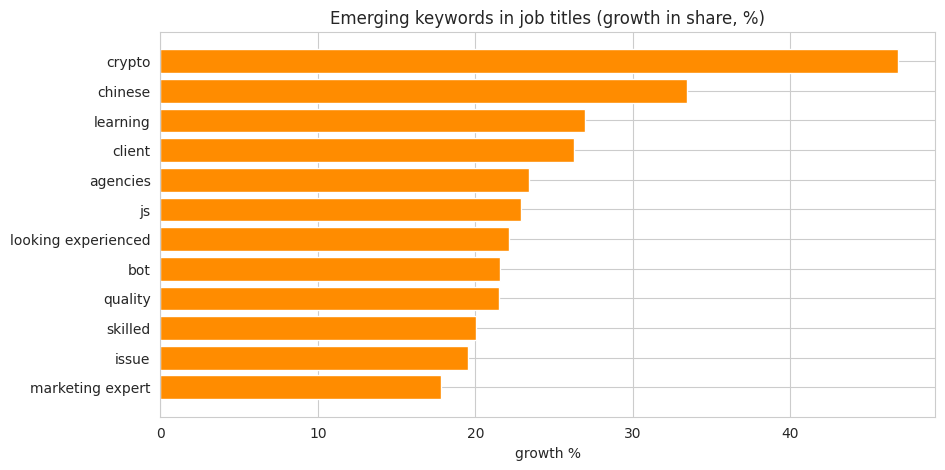

In [ ]:
plot_kw = emerging.head(12)
plt.figure(figsize=(10, 5))
plt.barh(plot_kw.index[::-1], plot_kw['growth_%'][::-1], color='darkorange')
plt.title('Emerging keywords in job titles (growth in share, %)')
plt.xlabel('growth %')
plt.show()

results['t2_emerging'] = plot_kw['growth_%'].round(1).to_dict()
results['t2_declining'] = declining.head(8)['growth_%'].round(1).to_dict()

## Task 3: Predict high-demand job roles



In [ ]:
daily = df[(df['date'] >= '2024-02-16') & (df['date'] <= '2024-03-23') & (df['category'] != 'Other')]
daily_counts = daily.groupby(['date', 'category']).size().unstack(fill_value=0)
print(daily_counts.shape)

rows = []
for cat in daily_counts.columns:
    s = daily_counts[cat]
    for i in range(7, len(s)):
        rows.append({'date': s.index[i], 'category': cat,
                     'lag1': s.iloc[i - 1], 'lag7': s.iloc[i - 7],
                     'avg7': s.iloc[i - 7:i].mean(), 'dayofweek': s.index[i].dayofweek,
                     'jobs': s.iloc[i]})
data = pd.DataFrame(rows)
data = pd.concat([data, pd.get_dummies(data['category']).astype(int)], axis=1)

feature_cols = ['lag1', 'lag7', 'avg7', 'dayofweek'] + list(daily_counts.columns)
split_date = pd.Timestamp('2024-03-17')
train = data[data['date'] < split_date]
test = data[data['date'] >= split_date].copy()
print('train rows:', len(train), ' test rows:', len(test))

(37, 15)
train rows: 345  test rows: 105


In [ ]:
model = RandomForestRegressor(n_estimators=200, random_state=42)
model.fit(train[feature_cols], train['jobs'])
test['predicted'] = model.predict(test[feature_cols])
test['baseline'] = test['lag7']


def show_scores(actual, pred):
    mae = mean_absolute_error(actual, pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))
    mape = np.mean(np.abs(actual - pred) / actual) * 100
    r2 = r2_score(actual, pred)
    return {'MAE': round(mae, 1), 'RMSE': round(rmse, 1), 'MAPE %': round(mape, 1), 'R2': round(r2, 3)}


scores = pd.DataFrame({'Random Forest': show_scores(test['jobs'], test['predicted']),
                       'Baseline (last week)': show_scores(test['jobs'], test['baseline'])})
scores

,Random Forest,Baseline (last week)
MAE,21.800,24.100
RMSE,30.200,33.400
MAPE %,8.900,9.000
R2,0.989,0.986


In [ ]:
# can the model find the top 5 categories of the test week?
actual_top5 = test.groupby('category')['jobs'].sum().sort_values(ascending=False).head(5).index.tolist()
pred_top5 = test.groupby('category')['predicted'].sum().sort_values(ascending=False).head(5).index.tolist()
print('actual top 5   :', actual_top5)
print('predicted top 5:', pred_top5)
print('matching categories:', len(set(actual_top5) & set(pred_top5)), 'out of 5')

results['t3_scores'] = scores.to_dict()
results['t3_top5_match'] = len(set(actual_top5) & set(pred_top5))

actual top 5   : ['Web & Software Development', 'Graphic Design', 'Video Editing & Animation', 'Writing & Translation', 'Social Media & Marketing']
predicted top 5: ['Web & Software Development', 'Graphic Design', 'Video Editing & Animation', 'Writing & Translation', 'Social Media & Marketing']
matching categories: 5 out of 5


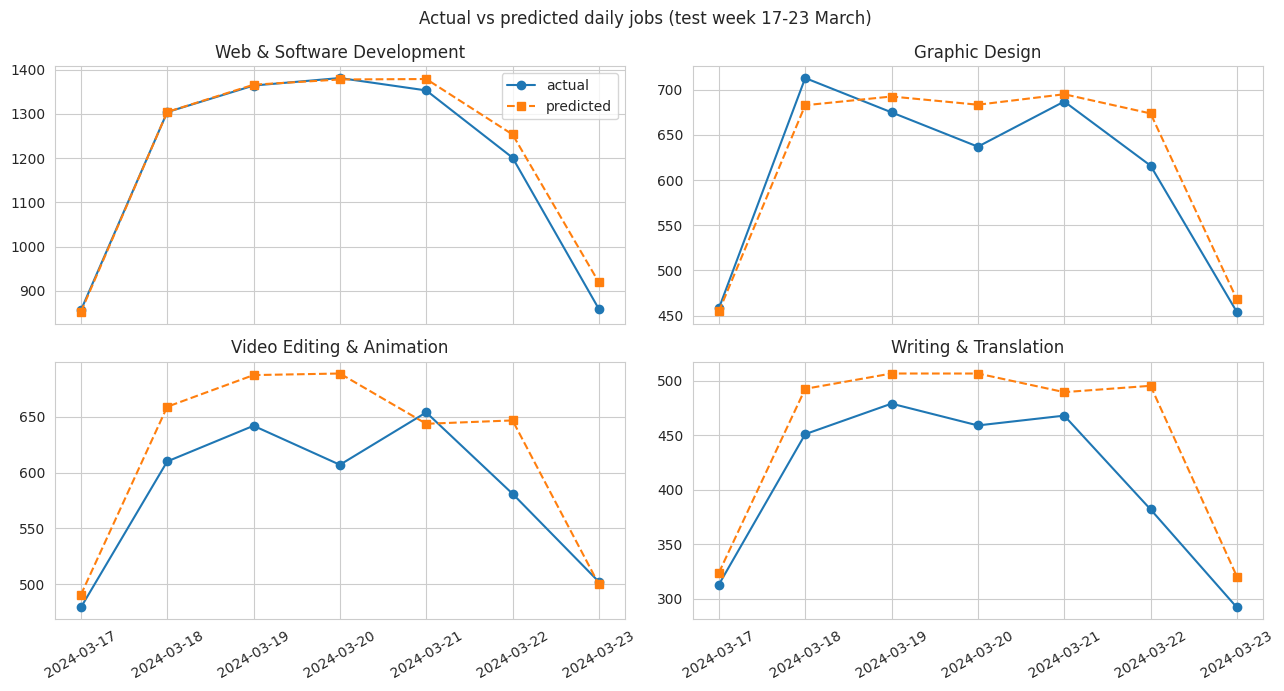

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for ax, cat in zip(axes.ravel(), actual_top5[:4]):
    t = test[test['category'] == cat].sort_values('date')
    ax.plot(t['date'], t['jobs'], marker='o', label='actual')
    ax.plot(t['date'], t['predicted'], marker='s', linestyle='--', label='predicted')
    ax.set_title(cat)
    ax.tick_params(axis='x', rotation=30)
axes[0, 0].legend()
plt.suptitle('Actual vs predicted daily jobs (test week 17-23 March)')
plt.tight_layout()
plt.show()

### Forecast for the next 7 days

In [ ]:
# train again on all data, then predict day by day (each prediction is used for the next day)
model.fit(data[feature_cols], data['jobs'])

history = {cat: list(daily_counts[cat]) for cat in daily_counts.columns}
last_date = daily_counts.index[-1]
forecast_rows = []

for step in range(1, 8):
    day = last_date + pd.Timedelta(days=step)
    for cat in history:
        h = history[cat]
        row = {'lag1': h[-1], 'lag7': h[-7], 'avg7': np.mean(h[-7:]), 'dayofweek': day.dayofweek}
        for c in daily_counts.columns:
            row[c] = 1 if c == cat else 0
        pred = model.predict(pd.DataFrame([row])[feature_cols])[0]
        history[cat].append(pred)
        forecast_rows.append({'date': day, 'category': cat, 'predicted_jobs': pred})

forecast = pd.DataFrame(forecast_rows)
next_week = forecast.groupby('category')['predicted_jobs'].sum()
last_week = daily_counts.tail(7).sum()
demand = pd.DataFrame({'last_7_days': last_week, 'next_7_days_forecast': next_week}).round(0)
demand['change_%'] = ((demand['next_7_days_forecast'] - demand['last_7_days']) / demand['last_7_days'] * 100).round(1)
demand = demand.sort_values('next_7_days_forecast', ascending=False)
demand

,last_7_days,next_7_days_forecast,change_%
category,,,
Web & Software Development,8318,8443.0,1.5
Graphic Design,4240,4262.0,0.5
Video Editing & Animation,4075,4059.0,-0.4
Writing & Translation,2844,2477.0,-12.9
Social Media & Marketing,2206,2123.0,-3.8
Data & Analytics,2104,2121.0,0.8
E-commerce,2090,2080.0,-0.5
Mobile App Development,1966,2011.0,2.3
Sales & Lead Generation,1886,1876.0,-0.5


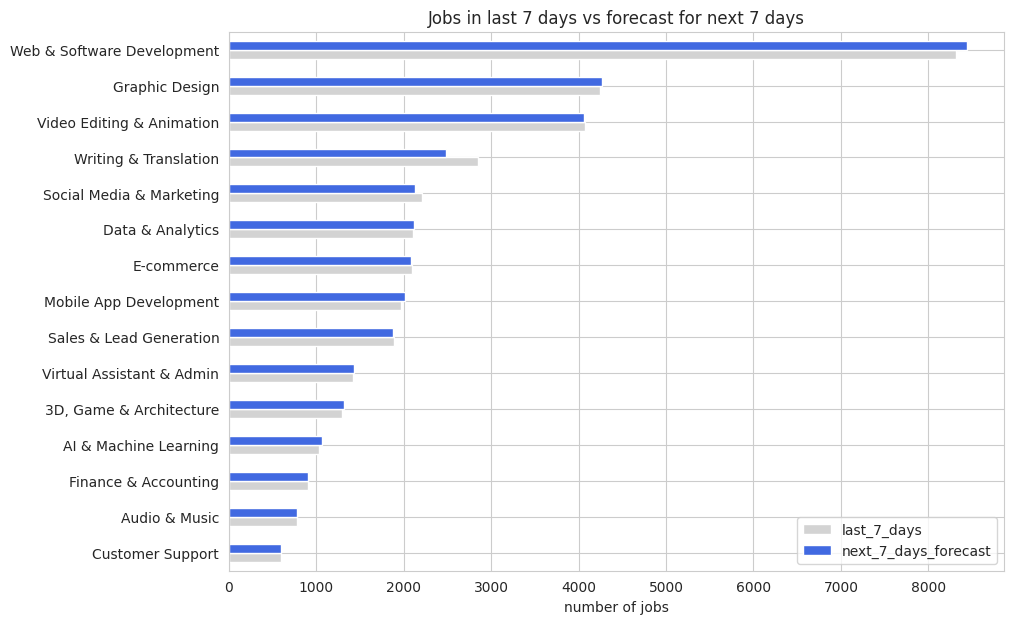

In [ ]:
demand[['last_7_days', 'next_7_days_forecast']][::-1].plot(kind='barh', figsize=(10, 7), color=['lightgray', 'royalblue'])
plt.title('Jobs in last 7 days vs forecast for next 7 days')
plt.xlabel('number of jobs')
plt.ylabel('')
plt.show()

results['t3_demand'] = demand.head(8)[['last_7_days', 'next_7_days_forecast']].to_dict('index')

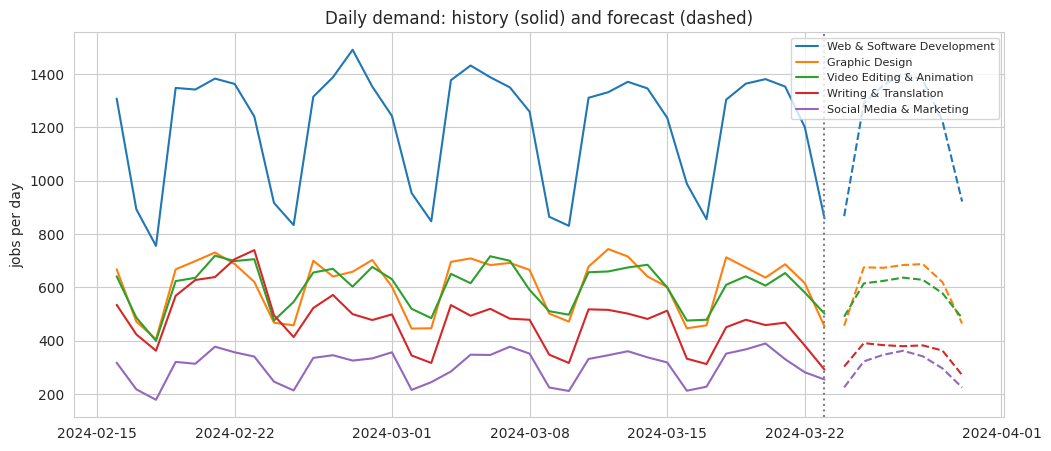

In [ ]:
# demand trend over time with the forecast, top 5 categories
top5 = demand.head(5).index.tolist()
plt.figure(figsize=(12, 5))
for cat in top5:
    line = plt.plot(daily_counts.index, daily_counts[cat], label=cat)
    f = forecast[forecast['category'] == cat]
    plt.plot(f['date'], f['predicted_jobs'], linestyle='--', color=line[0].get_color())
plt.axvline(last_date, color='gray', linestyle=':')
plt.title('Daily demand: history (solid) and forecast (dashed)')
plt.ylabel('jobs per day')
plt.legend(fontsize=8)
plt.show()

**Insight:** The weekly cycle (high on weekdays, low on weekends) continues in the forecast. No sudden jump or fall is expected for the top categories in the next week.

## Task 4: Average hourly rate by country



In [ ]:
country_rate = hourly.groupby('country')['hourly_rate'].agg(['count', 'mean', 'median']).round(2)
country_rate = country_rate[country_rate['count'] >= 100].sort_values('median', ascending=False)
country_rate = country_rate.reset_index()
print('countries used:', len(country_rate))
country_rate.head(10)

countries used: 59


,country,count,mean,median
0,Latvia,111,31.71,30.00
1,Vietnam,253,29.92,27.50
2,Kenya,368,30.47,26.25
3,Poland,414,27.30,25.00
4,Saudi Arabia,423,28.14,25.00
5,Ukraine,577,30.18,25.00
6,United States,47695,30.18,25.00
7,Morocco,142,26.70,25.00
8,Cyprus,166,28.26,25.00
9,Turkey,381,25.85,25.00


In [ ]:
fig = px.choropleth(country_rate, locations='country', locationmode='country names',
                    color='median', hover_data=['mean', 'count'],
                    color_continuous_scale='YlOrRd',
                    title='Median hourly rate offered, by client country (USD)')
fig.update_layout(height=500, margin=dict(l=0, r=0, t=50, b=0))
fig.write_html('hourly_rate_map.html')
fig.show()

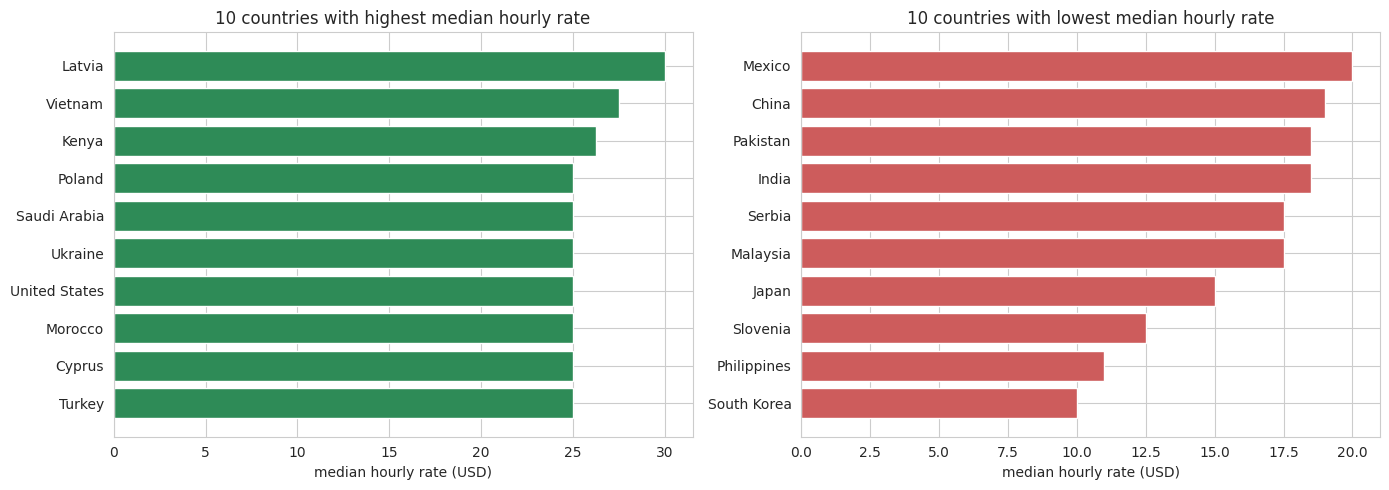

In [ ]:
top10 = country_rate.head(10)
bottom10 = country_rate.tail(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(top10['country'][::-1], top10['median'][::-1], color='seagreen')
axes[0].set_title('10 countries with highest median hourly rate')
axes[1].barh(bottom10['country'][::-1], bottom10['median'][::-1], color='indianred')
axes[1].set_title('10 countries with lowest median hourly rate')
for ax in axes:
    ax.set_xlabel('median hourly rate (USD)')
plt.tight_layout()
plt.show()

results['t4_top'] = top10[['country', 'median', 'mean', 'count']].to_dict('records')
results['t4_bottom'] = bottom10[['country', 'median', 'mean', 'count']].to_dict('records')

In [ ]:
# big countries, by number of hourly jobs
big_countries = country_rate.sort_values('count', ascending=False).head(10)
big_countries[['country', 'count', 'mean', 'median']]

,country,count,mean,median
6,United States,47695,30.18,25.0
27,United Kingdom,8311,27.50,22.5
40,Australia,5880,23.74,20.0
34,Canada,5203,25.11,21.0
52,India,4418,21.96,18.5
25,Germany,2073,27.09,22.5
45,Netherlands,1609,22.12,20.0
51,Pakistan,1434,22.52,18.5
31,United Arab Emirates,1290,25.02,22.0
42,France,1255,24.63,20.0


In [ ]:
results['t4_big'] = big_countries[['country', 'median', 'mean', 'count']].to_dict('records')

## Task 5: Job recommendation engine


In [ ]:
jobs = df.sort_values('published_date', ascending=False).drop_duplicates('title_clean').reset_index(drop=True)
jobs['job_type'] = np.where(jobs['is_hourly'], 'Hourly', 'Fixed')
jobs['pay'] = np.where(jobs['is_hourly'], jobs['hourly_rate'], jobs['budget'])
print('unique jobs for recommendation:', len(jobs))

tfidf = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), min_df=2)
job_matrix = tfidf.fit_transform(jobs['title_clean'])
print('matrix shape:', job_matrix.shape)

unique jobs for recommendation: 201136


matrix shape: (201136, 103327)


In [ ]:
def recommend(skills, job_type='any', min_hourly=0, country=None, top_n=10):
    query = tfidf.transform([skills.lower()])
    scores = cosine_similarity(query, job_matrix).ravel()

    keep = scores > 0
    if job_type == 'hourly':
        keep = keep & jobs['is_hourly'].values
    elif job_type == 'fixed':
        keep = keep & (~jobs['is_hourly'].values)
    if min_hourly > 0:
        keep = keep & (jobs['hourly_rate'].fillna(0).values >= min_hourly)
    if country:
        keep = keep & (jobs['country'] == country).values

    index = np.where(keep)[0]
    index = index[np.argsort(-scores[index], kind='stable')][:top_n]

    out = jobs.loc[index, ['title', 'category', 'job_type', 'pay', 'country', 'link']].copy()
    out['match_score'] = scores[index].round(3)
    return out.reset_index(drop=True)


pd.set_option('display.max_colwidth', 60)
recommend('python data analysis pandas', top_n=5)[['title', 'category', 'job_type', 'pay', 'country', 'match_score']]

,title,category,job_type,pay,country,match_score
0,Python Data Analysis,Data & Analytics,Fixed,200.0,United States,0.825
1,Python Data Analysis - Restaurant Sales Data,Data & Analytics,Fixed,45.0,United States,0.634
2,Data Analysis,Data & Analytics,Hourly,34.0,Kenya,0.573
3,Data analysis in R,Data & Analytics,Fixed,35.0,Austria,0.573
4,Cytoflow Data Analysis,Data & Analytics,Fixed,15.0,Singapore,0.573


In [ ]:
recommend('wordpress website developer', job_type='hourly', min_hourly=30, top_n=5)[['title', 'job_type', 'pay', 'country', 'match_score']]

,title,job_type,pay,country,match_score
0,Website Developer,Hourly,30.0,United States,0.754
1,Website developer for wordpress,Hourly,30.0,United States,0.628
2,Website developer and designer,Hourly,30.5,Bulgaria,0.517
3,Website Developer/Designer,Hourly,30.5,Pakistan,0.517
4,Expert Website Developer,Hourly,30.0,United States,0.513


In [ ]:
recommend('youtube video editor', country='United States', top_n=5)[['title', 'job_type', 'pay', 'country', 'match_score']]

,title,job_type,pay,country,match_score
0,YouTube Video Editor,Fixed,14.0,United States,1.0
1,YouTube video editor.,Hourly,20.0,United States,1.0
2,YouTube Video Editor 🎬,Hourly,NaN,United States,1.0
3,YouTube Video Editor 💻,Hourly,NaN,United States,1.0
4,YouTube Video Editor ✍️,Fixed,15.0,United States,1.0


### Quick check of the recommendations


In [ ]:
tests = {
    'python data analysis pandas': 'Data & Analytics',
    'wordpress website developer': 'Web & Software Development',
    'youtube video editor': 'Video Editing & Animation',
    'logo design branding': 'Graphic Design',
    'blog article writer': 'Writing & Translation',
    'virtual assistant admin': 'Virtual Assistant & Admin',
    'shopify store': 'E-commerce',
    'chatgpt ai automation': 'AI & Machine Learning',
}
check_rows = []
for query, expected in tests.items():
    r = recommend(query, top_n=10)
    match = (r['category'] == expected).mean() * 100
    check_rows.append({'user searches for': query, 'expected category': expected, 'results': len(r), 'match %': match})
check = pd.DataFrame(check_rows)
print(check)
print()
print('average match %:', round(check['match %'].mean(), 1))

results['t5_check'] = check[['user searches for', 'match %']].to_dict('records')
results['t5_avg_match'] = round(float(check['match %'].mean()), 1)
sample = recommend('python data analysis pandas', top_n=5)
results['t5_sample_query'] = 'python data analysis pandas'
results['t5_sample'] = sample[['title', 'job_type', 'pay', 'country', 'match_score']].to_dict('records')

             user searches for           expected category  results  match %
0  python data analysis pandas            Data & Analytics       10    100.0
1  wordpress website developer  Web & Software Development       10    100.0
2         youtube video editor   Video Editing & Animation       10    100.0
3         logo design branding              Graphic Design       10     90.0
4          blog article writer       Writing & Translation       10     50.0
5      virtual assistant admin   Virtual Assistant & Admin       10     60.0
6                shopify store                  E-commerce       10    100.0
7        chatgpt ai automation       AI & Machine Learning       10    100.0

average match %: 87.5


## Task 6: Track changes in job market over time



In [ ]:
weekly = df.groupby('week').agg(jobs=('title', 'size'),
                                hourly_share=('is_hourly', 'mean'),
                                median_hourly_rate=('hourly_rate', 'median'),
                                median_budget=('budget', 'median'))
weekly['hourly_share'] = weekly['hourly_share'] * 100
weekly['days'] = df.groupby('week')['date'].nunique()
weekly['jobs_per_day'] = (weekly['jobs'] / weekly['days']).round(0)
weekly.index = [week_start[w] for w in weekly.index]
weekly.round(2)

,jobs,hourly_share,median_hourly_rate,median_budget,days,jobs_per_day
13 Feb,35199,58.47,22.5,100.0,7,5028.0
20 Feb,45479,58.58,22.5,100.0,7,6497.0
27 Feb,43704,57.08,22.5,100.0,7,6243.0
05 Mar,43675,57.65,22.5,100.0,7,6239.0
12 Mar,42989,56.28,22.5,100.0,7,6141.0
19 Mar,33481,57.27,22.5,100.0,6,5580.0


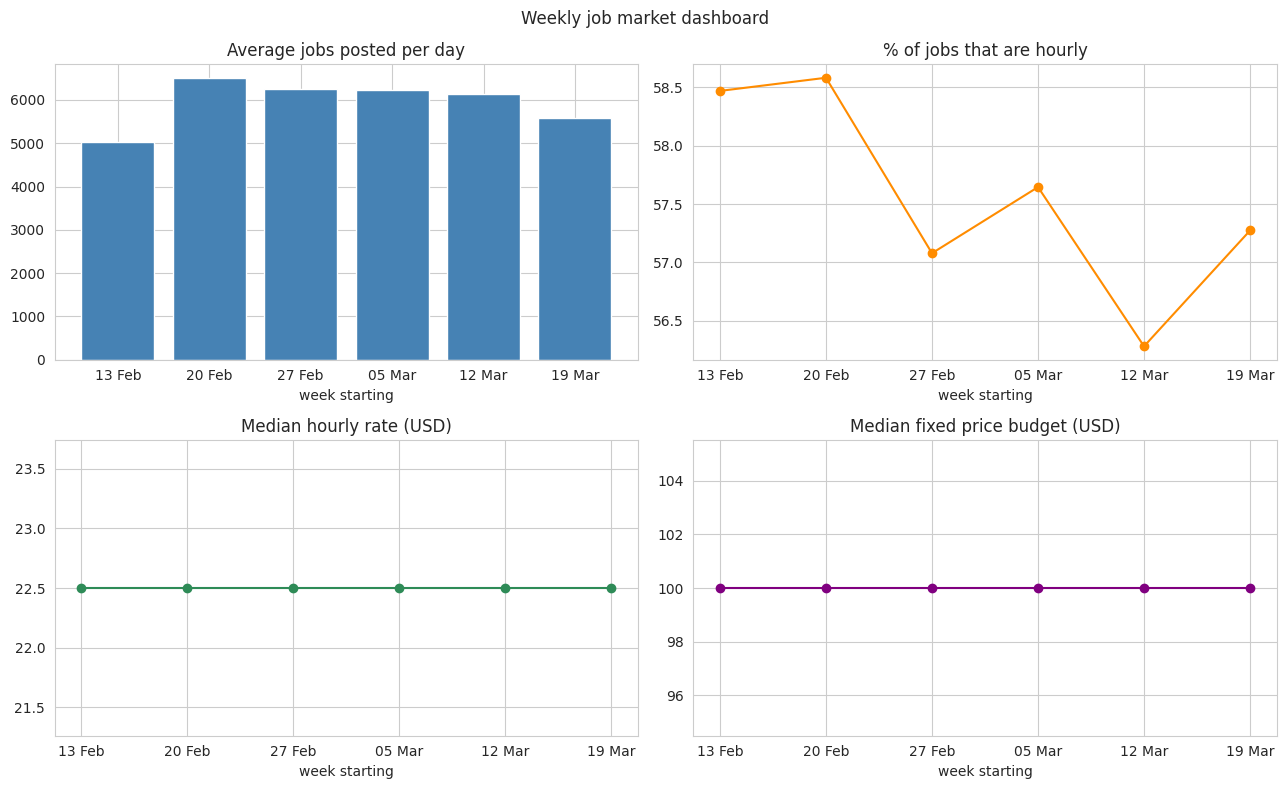

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

axes[0, 0].bar(weekly.index, weekly['jobs_per_day'], color='steelblue')
axes[0, 0].set_title('Average jobs posted per day')

axes[0, 1].plot(weekly.index, weekly['hourly_share'], marker='o', color='darkorange')
axes[0, 1].set_title('% of jobs that are hourly')

axes[1, 0].plot(weekly.index, weekly['median_hourly_rate'], marker='o', color='seagreen')
axes[1, 0].set_title('Median hourly rate (USD)')

axes[1, 1].plot(weekly.index, weekly['median_budget'], marker='o', color='purple')
axes[1, 1].set_title('Median fixed price budget (USD)')

for ax in axes.ravel():
    ax.set_xlabel('week starting')
plt.suptitle('Weekly job market dashboard')
plt.tight_layout()
plt.show()

results['t6_weekly'] = {
    'weeks': list(weekly.index),
    'jobs_per_day': weekly['jobs_per_day'].tolist(),
    'hourly_share': weekly['hourly_share'].round(1).tolist(),
    'median_hourly_rate': weekly['median_hourly_rate'].round(2).tolist(),
    'median_budget': weekly['median_budget'].round(1).tolist(),
}

In [ ]:
# month wise comparison (Feb has only 17 days of data, so use per day numbers)
monthly = df.groupby('month').agg(jobs=('title', 'size'), days=('date', 'nunique'),
                                  hourly_share=('is_hourly', 'mean'),
                                  median_hourly_rate=('hourly_rate', 'median'),
                                  median_budget=('budget', 'median'))
monthly['jobs_per_day'] = (monthly['jobs'] / monthly['days']).round(0)
monthly['hourly_share'] = (monthly['hourly_share'] * 100).round(1)
monthly = monthly.loc[['Feb 2024', 'Mar 2024']]
print(monthly)

# change in category share between Feb and Mar
month_cat = pd.crosstab(df['month'], df['category'], normalize='index').drop(columns='Other') * 100
month_change = (month_cat.loc['Mar 2024'] - month_cat.loc['Feb 2024']).sort_values()
month_change.round(2)

            jobs  days  hourly_share  median_hourly_rate  median_budget  \
month                                                                     
Feb 2024  101703    17          58.3                22.5          100.0   
Mar 2024  142824    24          57.0                22.5          100.0   

          jobs_per_day  
month                   
Feb 2024        5983.0  
Mar 2024        5951.0  


category
Writing & Translation        -1.27
Data & Analytics             -0.55
Audio & Music                -0.04
Virtual Assistant & Admin    -0.02
Sales & Lead Generation       0.00
Mobile App Development        0.02
3D, Game & Architecture       0.04
Customer Support              0.06
E-commerce                    0.10
Finance & Accounting          0.15
Social Media & Marketing      0.20
AI & Machine Learning         0.20
Graphic Design                0.26
Video Editing & Animation     0.26
Web & Software Development    0.35
dtype: float64

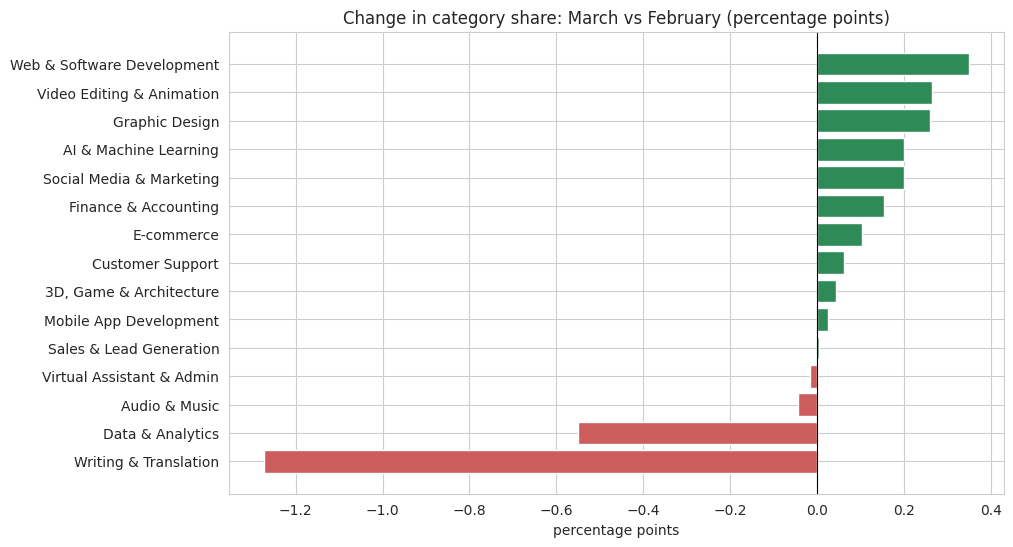

In [ ]:
colors = ['seagreen' if v > 0 else 'indianred' for v in month_change]
plt.figure(figsize=(10, 6))
plt.barh(month_change.index, month_change.values, color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Change in category share: March vs February (percentage points)')
plt.xlabel('percentage points')
plt.show()

results['t6_month_change'] = month_change.round(2).to_dict()
results['t6_monthly'] = monthly.reset_index().to_dict('records')

## Task 7: Remote work trends


In [ ]:
remote_words = r'remote|work from home|\bwfh\b|work-from-home|virtual team'
longterm_words = r'long term|long-term|full time|full-time|ongoing|permanent|part time|part-time|monthly retainer'

df['is_remote_title'] = df['title_clean'].str.contains(remote_words, regex=True)
df['is_longterm'] = df['title_clean'].str.contains(longterm_words, regex=True)

print('jobs mentioning remote   :', df['is_remote_title'].sum(), '(', round(df['is_remote_title'].mean() * 100, 2), '% )')
print('long term / full time jobs:', df['is_longterm'].sum(), '(', round(df['is_longterm'].mean() * 100, 2), '% )')

remote_week = df.groupby('week').agg(remote_share=('is_remote_title', 'mean'),
                                     longterm_share=('is_longterm', 'mean'),
                                     hourly_share=('is_hourly', 'mean')) * 100
remote_week.index = [week_start[w] for w in remote_week.index]
remote_week.round(2)

jobs mentioning remote   : 1376 ( 0.56 % )
long term / full time jobs: 4471 ( 1.83 % )


,remote_share,longterm_share,hourly_share
13 Feb,0.59,2.05,58.47
20 Feb,0.55,1.75,58.58
27 Feb,0.53,1.86,57.08
05 Mar,0.54,1.78,57.65
12 Mar,0.58,1.84,56.28
19 Mar,0.59,1.71,57.27


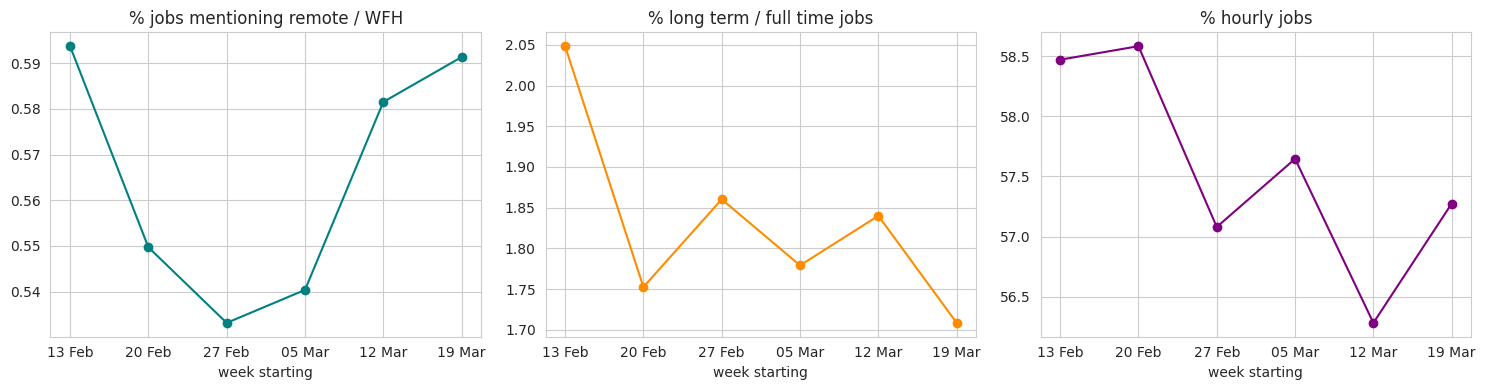

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(remote_week.index, remote_week['remote_share'], marker='o', color='teal')
axes[0].set_title('% jobs mentioning remote / WFH')
axes[1].plot(remote_week.index, remote_week['longterm_share'], marker='o', color='darkorange')
axes[1].set_title('% long term / full time jobs')
axes[2].plot(remote_week.index, remote_week['hourly_share'], marker='o', color='purple')
axes[2].set_title('% hourly jobs')
for ax in axes:
    ax.set_xlabel('week starting')
plt.tight_layout()
plt.show()

results['t7_weekly'] = {k: remote_week[k].round(2).tolist() for k in remote_week.columns}

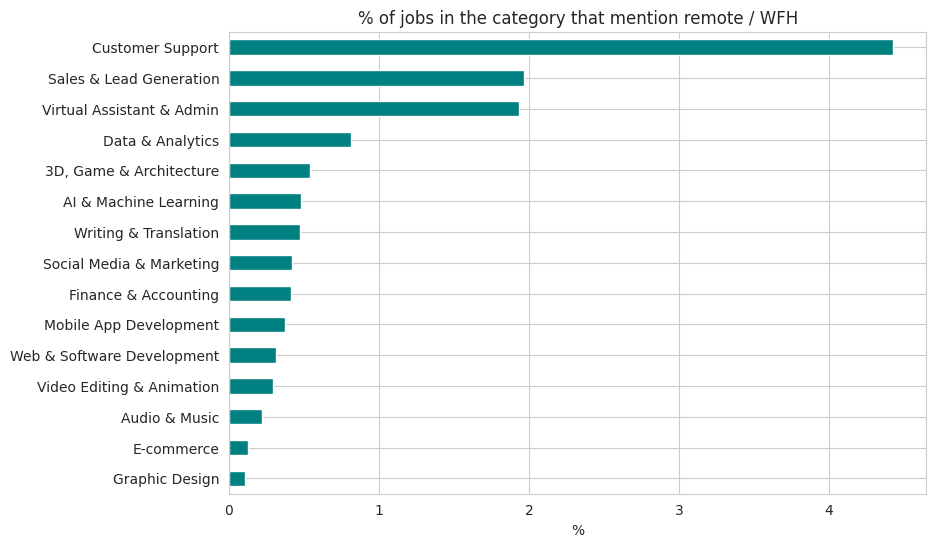

In [ ]:
# which categories use the word remote the most
remote_cat = df.groupby('category')['is_remote_title'].mean().drop('Other') * 100
remote_cat = remote_cat.sort_values()
remote_cat.plot(kind='barh', color='teal', figsize=(9, 6))
plt.title('% of jobs in the category that mention remote / WFH')
plt.xlabel('%')
plt.ylabel('')
plt.show()

results['t7_cat'] = remote_cat.round(2).to_dict()

In [ ]:
# are clients becoming more global? share of top countries each week
top_countries = df['country'].value_counts().head(5).index
country_week = pd.crosstab(df['week'], df['country'], normalize='index')[top_countries] * 100
country_week['All other countries'] = 100 - country_week.sum(axis=1)
country_week.index = [week_start[w] for w in country_week.index]
country_week.round(1)

country,United States,United Kingdom,India,Australia,Canada,All other countries
13 Feb,42.2,8.1,6.5,5.0,4.7,33.5
20 Feb,40.8,7.6,7.1,5.4,4.7,34.3
27 Feb,42.0,8.2,6.3,5.2,5.0,33.4
05 Mar,42.3,7.9,6.5,5.1,5.0,33.2
12 Mar,41.3,8.2,6.6,5.4,4.9,33.7
19 Mar,41.3,7.9,6.6,5.5,5.0,33.7


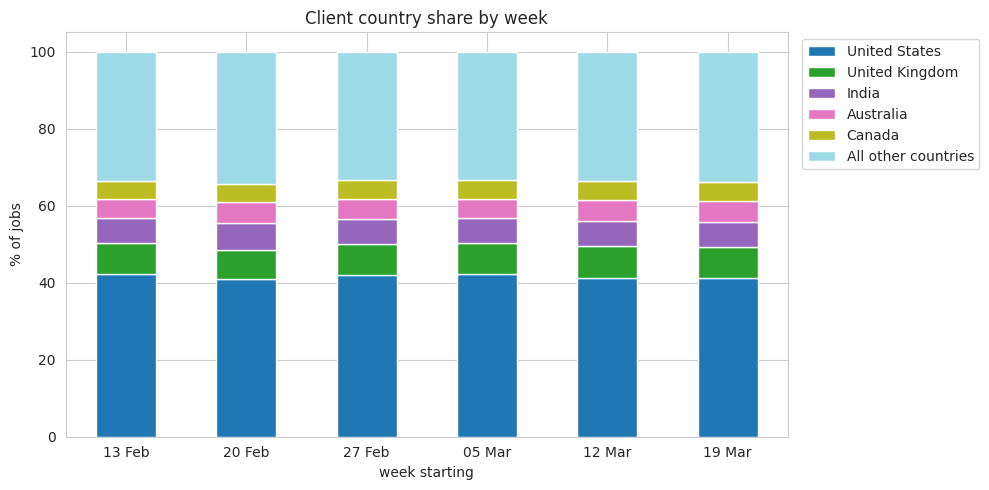

In [ ]:
country_week.plot(kind='bar', stacked=True, figsize=(10, 5), colormap='tab20')
plt.title('Client country share by week')
plt.ylabel('% of jobs')
plt.xlabel('week starting')
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Simple forecast of the remote signals (next 4 weeks)

In [ ]:
# linear trend on the weekly share. Only 6 points, so this is a rough guide only.
weeks_known = np.arange(1, 7).reshape(-1, 1)
weeks_next = np.arange(7, 11).reshape(-1, 1)
remote_forecast = {}

for col in ['remote_share', 'longterm_share', 'hourly_share']:
    lr = LinearRegression().fit(weeks_known, remote_week[col].values)
    pred = lr.predict(weeks_next)
    remote_forecast[col] = pred.round(2).tolist()
    print(col, '-> slope per week:', round(lr.coef_[0], 3), '| next 4 weeks:', pred.round(2))

results['t7_forecast'] = remote_forecast

remote_share -> slope per week: 0.003 | next 4 weeks: [0.57 0.58 0.58 0.58]
longterm_share -> slope per week: -0.043 | next 4 weeks: [1.68 1.64 1.59 1.55]
hourly_share -> slope per week: -0.352 | next 4 weeks: [56.32 55.97 55.62 55.27]


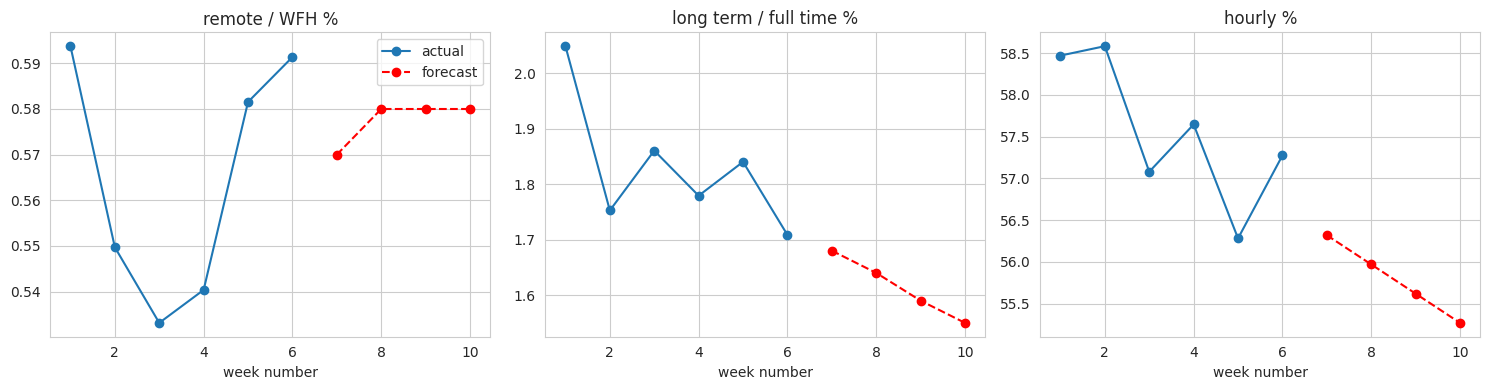

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in zip(axes, ['remote_share', 'longterm_share', 'hourly_share'],
                          ['remote / WFH %', 'long term / full time %', 'hourly %']):
    ax.plot(range(1, 7), remote_week[col].values, marker='o', label='actual')
    ax.plot(range(7, 11), remote_forecast[col], marker='o', linestyle='--', color='red', label='forecast')
    ax.set_title(title)
    ax.set_xlabel('week number')
axes[0].legend()
plt.tight_layout()
plt.show()

**Insight:** The linear forecast keeps the remote share at about 0.58%, long term jobs slowly down to 1.55% and hourly jobs to about 55.3% in 4 weeks. The slopes are very small and there are only 6 points, so the safe reading is: remote signals are stable, no strong change expected.

## Task 8: Predict future job market trends

Here I combine the earlier results. For each category I fit a linear trend on its weekly share and project it 4 weeks ahead (to week 10, 16-22 April 2024) under three scenarios:

- **Same trend**: the weekly change stays the same as now.
- **Weaker trend**: the weekly change becomes half.
- **Stronger trend**: the weekly change becomes 1.5 times.

For a falling category, "stronger trend" means it falls faster.

I also look at the overall market (volume of jobs, hourly rate).

In [ ]:
weeks_known = np.arange(1, 7).reshape(-1, 1)
scenario_rows = []
for cat in week_cat.columns:
    lr = LinearRegression().fit(weeks_known, week_cat[cat].values)
    slope = lr.coef_[0]
    now = week_cat[cat].values[-3:].mean()       # current level = last 3 weeks average
    steps = 10 - 5                                # from middle of last 3 weeks (week 5) to week 10
    scenario_rows.append({'category': cat, 'share_now_%': now, 'slope_per_week': slope,
                          'weaker_trend': now + slope * 0.5 * steps,
                          'same_trend': now + slope * steps,
                          'stronger_trend': now + slope * 1.5 * steps})
scenario = pd.DataFrame(scenario_rows).set_index('category')
scenario['change_if_continues_%'] = (scenario['same_trend'] - scenario['share_now_%']) / scenario['share_now_%'] * 100
scenario = scenario.sort_values('change_if_continues_%', ascending=False)
scenario.round(2)

,share_now_%,slope_per_week,weaker_trend,same_trend,stronger_trend,change_if_continues_%
category,,,,,,
Customer Support,1.31,0.04,1.40,1.48,1.57,13.46
AI & Machine Learning,2.46,0.04,2.56,2.66,2.76,8.24
Social Media & Marketing,5.06,0.06,5.22,5.38,5.54,6.23
Finance & Accounting,2.11,0.02,2.17,2.23,2.29,5.46
E-commerce,4.79,0.04,4.89,4.99,5.09,4.15
Sales & Lead Generation,4.32,0.03,4.39,4.46,4.52,3.16
Mobile App Development,4.65,0.03,4.72,4.79,4.86,2.88
Web & Software Development,19.54,0.11,19.82,20.09,20.36,2.78
Graphic Design,9.99,0.04,10.09,10.20,10.31,2.15


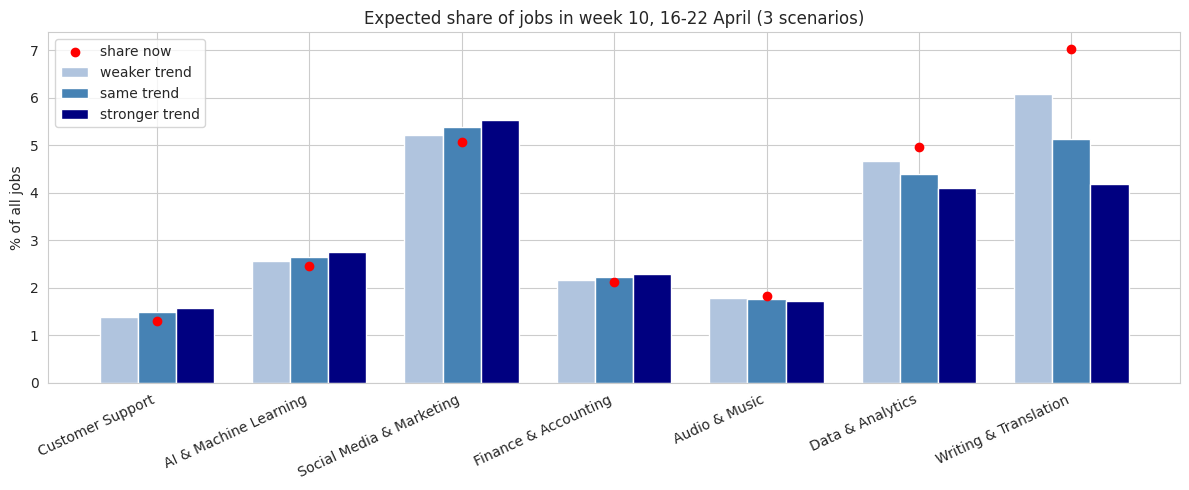

In [ ]:
show = pd.concat([scenario.head(4), scenario.tail(3)])

x = np.arange(len(show))
plt.figure(figsize=(12, 5))
plt.bar(x - 0.25, show['weaker_trend'], width=0.25, label='weaker trend', color='lightsteelblue')
plt.bar(x, show['same_trend'], width=0.25, label='same trend', color='steelblue')
plt.bar(x + 0.25, show['stronger_trend'], width=0.25, label='stronger trend', color='navy')
plt.scatter(x, show['share_now_%'], color='red', zorder=5, label='share now')
plt.xticks(x, show.index, rotation=25, ha='right')
plt.ylabel('% of all jobs')
plt.title('Expected share of jobs in week 10, 16-22 April (3 scenarios)')
plt.legend()
plt.tight_layout()
plt.show()

results['t8_scenario'] = show[['share_now_%', 'weaker_trend', 'same_trend', 'stronger_trend']].round(2).to_dict('index')

**Insight:** If the current trend continues, Customer Support grows from 1.31% to 1.48% of jobs (+13%) and AI from 2.46% to 2.66% (+8%), while Writing & Translation falls from 7.03% to 5.14% (-27%) and Data & Analytics from 4.96% to 4.39% (-12%). The direction is the same in all three scenarios, only the size changes.

In [ ]:
# overall market: jobs per day and hourly rate trend, with a simple projection
x_weeks = np.arange(1, 7).reshape(-1, 1)
out = {}
for col in ['jobs_per_day', 'median_hourly_rate']:
    lr = LinearRegression().fit(x_weeks, weekly[col].values)
    out[col] = {'slope': round(float(lr.coef_[0]), 3), 'week10': round(float(lr.predict([[10]])[0]), 2)}
print(out)

results['t8_market'] = out

{'jobs_per_day': {'slope': 48.229, 'week10': 6268.15}, 'median_hourly_rate': {'slope': 0.0, 'week10': 22.5}}


**Insight:** The overall posting volume trend is +48 jobs per day each week (about 6,270 per day in week 10), but this slope is pulled up by the weak first week, so the volume is more likely flat. The median hourly rate has no trend ($22.5), so no salary growth is expected.

### Summary of the future scenarios

| Scenario | What it means |
|---|---|
| Weaker trend | Growing categories grow at half speed and falling ones fall slowly, the market is almost stable |
| Same trend | Customer support, AI and marketing keep gaining share, writing and data keep losing |
| Stronger trend | The shift of demand becomes faster |

Remember that only 6 weeks of data is available, so these are directions, not exact predictions.

## Final conclusion

- **Salary and keywords:** titles with professional service words (tax, consultant, legal, engineer) pay the most, titles with assistant / virtual / lead / customer words pay the least. Finance and AI jobs have the highest median hourly rates ($30 and $27.5).
- **Emerging categories:** Customer Support (+7.7%), AI (+6.5%) and Social Media & Marketing (+4.7%) are gaining share; Writing & Translation (-14.4%) and Data & Analytics (-7%) are losing. Crypto, bot and js are the fastest growing title words.
- **High demand roles:** Web & Software Development, Graphic Design and Video Editing will stay the top 3 in the next week. The forecast model has 8.9% MAPE.
- **Countries:** US clients post almost 5 times more hourly jobs than any other country, and pay a median of $25. India and Pakistan clients offer $18.5, the Philippines and South Korea about $10-11.
- **Recommendation engine:** TF-IDF + cosine similarity gives the right category for 87.5% of test searches. It is also available as a Flask API with a web page.
- **Market tracking:** volume, median rate ($22.5) and median budget ($100) are stable week to week.
- **Remote work:** explicit remote jobs are only about 0.55% of titles and are flat. Customer Support, Sales and Virtual Assistant jobs mention it the most.
- **Future:** if the trends continue, Customer Support and AI will gain share, Writing and Data will lose share.

**Limitations:** the data covers only 6 weeks (13 Feb - 24 Mar 2024), so everything about the trend and the forecast is a short-term indication. Categories are made from title keywords (about 16% unclassified), and the data has no job description, skills or freelancer information.

In [ ]:
with open('results.json', 'w') as f:
    json.dump(results, f, indent=1, default=str)
print('results saved')

results saved
